
# 📩 Email Spam Detection

## project Objective
The objective of this project is to classify SMS messages as **Spam** or **Ham (Not Spam)** using Natural Language Processing (NLP) and machine learning. The model learns patterns from message text to identify unwanted or suspicious messages.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- TF-IDF Vectorization

## Models Used
- Multinomial Naive Bayes
- Logistic Regression


## 1. Importing Required Libraries

In this step, we import the Python libraries required for data manipulation, visualization, text preprocessing, feature extraction, machine learning, and model evaluation.

- Pandas and NumPy are used for data handling.
- Matplotlib and Seaborn are used for visualization.
- Scikit-learn provides text vectorization, classification algorithms, and evaluation metrics.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from google.colab import files

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

We upload the SMS Spam Collection dataset into Google Colab and load it into a Pandas DataFrame. We inspect the file's structure and standardize the column names to make further processing easier.

In [17]:
uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(r"C:\Users\yashverdhan\Downloads\spam.csv")

df = pd.read_csv(
    csv_files[0],
    encoding="latin-1"
)

print("Dataset loaded successfully!")
print("Original shape:", df.shape)
print("Original columns:", df.columns.tolist())

display(df.head())

Saving spam.csv to spam (1).csv
Dataset loaded successfully!
Original shape: (5572, 5)
Original columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## 3. Data Cleaning

The dataset may contain unnecessary columns and empty records. We retain only the message label and message text, rename them for clarity, remove missing and duplicate records, and standardize the labels.

In [18]:
# Keep only the required columns
if {"v1", "v2"}.issubset(df.columns):
    df = df[["v1", "v2"]].copy()
    df.columns = ["label", "message"]

elif {"label", "message"}.issubset(df.columns):
    df = df[["label", "message"]].copy()

else:
    raise ValueError(
        "Unexpected columns. Please check the uploaded dataset."
    )

# Remove missing and empty messages
df = df.dropna(subset=["label", "message"]).copy()

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    (df["message"] != "")
].copy()

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Cleaned shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts())

display(df.head())

Dataset cleaned successfully!
Cleaned shape: (5158, 2)

Label counts:
label
ham     4516
spam     642
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 4. Exploratory Data Analysis

Exploratory data analysis helps us understand the distribution of spam and legitimate messages. We examine the number of messages in each category before training the classifier.

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5158 entries, 0 to 5157
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5158 non-null   object
 1   message  5158 non-null   object
dtypes: object(2)
memory usage: 80.7+ KB

Missing values:
label      0
message    0
dtype: int64

Label distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


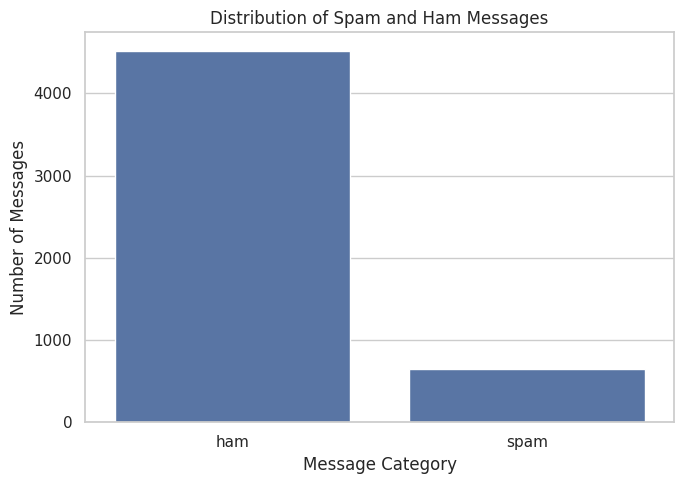

In [19]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

## 5. Message Length Analysis

Message length can help us understand differences between spam and legitimate messages. We calculate the number of characters in each message and compare the distributions across the two categories.

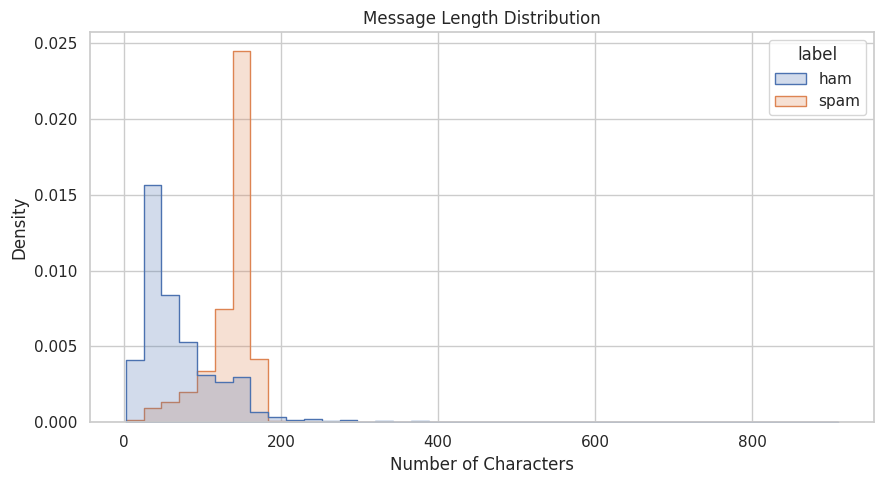

Average message length by category:


,message_length
label,
ham,70.42
spam,137.59


In [20]:
df["message_length"] = df["message"].str.len()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Message Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

print("Average message length by category:")
display(
    df.groupby("label")["message_length"]
      .mean()
      .round(2)
)

## 6. Text Preprocessing

Text preprocessing standardizes messages before feature extraction. We convert text to lowercase, remove URLs, remove punctuation and special characters, and normalize extra spaces. This helps reduce irrelevant variation between messages.

We retain the original message column so that the cleaned text can be compared with the original.

In [21]:
def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Keep letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_message"] = df["message"].apply(clean_text)

display(df[["message", "clean_message", "label"]].head(10))

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...,spam
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...,ham
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...,spam
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more u r entitled...,spam


## 7. Feature Selection and Target Encoding

The message text is our input feature, and the label is the target. We convert the labels into numerical values, where `0` represents ham and `1` represents spam. We then split the data into training and testing sets while preserving the class proportions.

In [22]:
X = df["clean_message"]
y = df["label"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nTarget mapping: ham = 0, spam = 1")

Training messages: 4126
Testing messages: 1032

Target mapping: ham = 0, spam = 1


## 8. Text Feature Extraction Using TF-IDF

Machine-learning algorithms cannot directly process raw text. TF-IDF (Term Frequency–Inverse Document Frequency) converts messages into numerical features based on the importance of words within messages and across the dataset.

The vectorizer is fitted only on the training messages to avoid leaking information from the test set.

In [23]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed!
Training matrix shape: (4126, 5000)
Testing matrix shape: (1032, 5000)


## 9. Model Training

We train two classification algorithms:

1. **Multinomial Naive Bayes:** A probabilistic classifier commonly used for text classification.
2. **Logistic Regression:** A classification algorithm that estimates the probability of a message belonging to a class.

Both models use the same TF-IDF features so their performance can be compared fairly.

In [24]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    trained_models[name] = model
    predictions[name] = y_pred

    print(f"{name} trained successfully!")

Multinomial Naive Bayes trained successfully!
Logistic Regression trained successfully!


## 10. Model Evaluation

We evaluate the models using accuracy, precision, recall, and F1-score.

- **Accuracy:** Percentage of correctly classified messages.
- **Precision:** How many messages predicted as spam were actually spam.
- **Recall:** How many actual spam messages were detected.
- **F1-score:** A balance between precision and recall.

Precision and recall are particularly important because incorrectly flagging a legitimate message as spam can be inconvenient, while missing spam can expose users to unwanted or misleading messages.

In [25]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.9690,1.000,0.7500,0.8571
1,Logistic Regression,0.9622,0.989,0.7031,0.8219


## 11. Classification Performance Comparison

We compare the accuracy, precision, recall, and F1-score of the two classifiers. This visualization makes it easier to understand their relative performance on the test data.

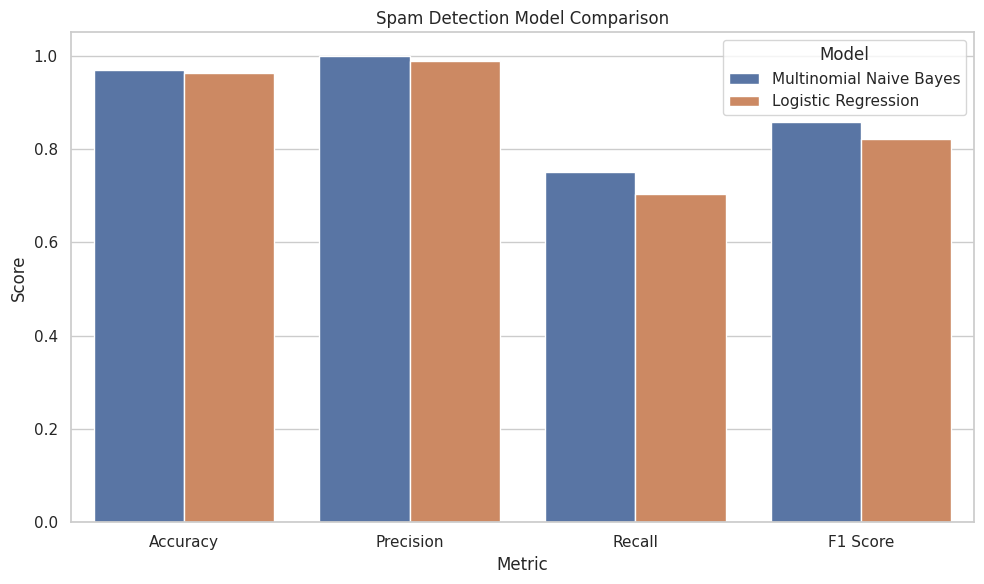

In [26]:
metrics_df = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Spam Detection Model Comparison")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## 12. Confusion Matrix and Classification Report

A confusion matrix shows correct and incorrect predictions for each class. It helps identify legitimate messages incorrectly classified as spam and spam messages incorrectly classified as legitimate. We also generate a classification report for each model.

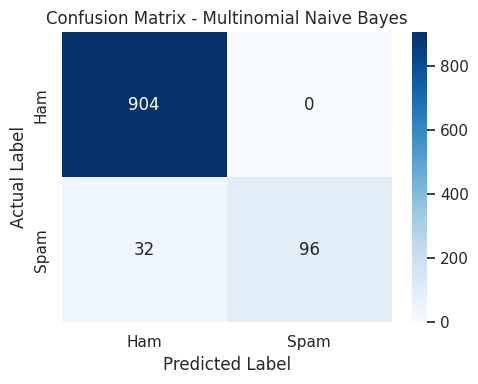


Classification Report - Multinomial Naive Bayes
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       904
        Spam       1.00      0.75      0.86       128

    accuracy                           0.97      1032
   macro avg       0.98      0.88      0.92      1032
weighted avg       0.97      0.97      0.97      1032



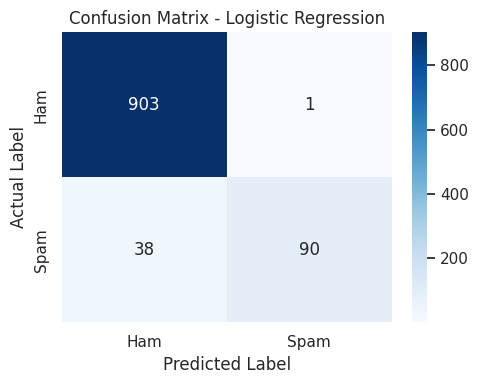


Classification Report - Logistic Regression
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       0.99      0.70      0.82       128

    accuracy                           0.96      1032
   macro avg       0.97      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032



In [27]:
for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    print(f"\nClassification Report - {name}")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            zero_division=0
        )
    )

## 13. Selecting the Best Model

We select the model with the highest test-set F1-score as our initial best model. F1-score considers both precision and recall, making it useful when comparing spam classifiers. We also review precision and recall before deciding whether the model is suitable for practical use.

In [28]:
best_index = results_df["F1 Score"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]
best_model = trained_models[best_model_name]

print("Best model by test F1-score:", best_model_name)
print(
    results_df.loc[
        best_index,
        ["Accuracy", "Precision", "Recall", "F1 Score"]
    ]
)

Best model by test F1-score: Multinomial Naive Bayes
Accuracy     0.968992
Precision         1.0
Recall           0.75
F1 Score     0.857143
Name: 0, dtype: object


## 14. Predicting New Messages

We test the selected classifier on new example messages. The input text is cleaned and converted using the same TF-IDF vectorizer used during training. The model then predicts whether each message is spam or legitimate.

These predictions are demonstrations and should not be treated as a guarantee that a message is safe or fraudulent.

In [29]:
def predict_message(message):
    cleaned = clean_text(message)
    features = tfidf.transform([cleaned])

    prediction = best_model.predict(features)[0]

    label = "SPAM" if prediction == 1 else "HAM (Legitimate)"
    return label


test_messages = [
    "Congratulations! You have won a free prize. Claim your reward now!",
    "Hey, are we meeting for college tomorrow?",
    "URGENT! You have been selected for a cash reward. Call now!",
    "Please send me the notes from today's class."
]

for message in test_messages:
    print("Message:", message)
    print("Prediction:", predict_message(message))
    print("-" * 60)

Message: Congratulations! You have won a free prize. Claim your reward now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting for college tomorrow?
Prediction: HAM (Legitimate)
------------------------------------------------------------
Message: URGENT! You have been selected for a cash reward. Call now!
Prediction: SPAM
------------------------------------------------------------
Message: Please send me the notes from today's class.
Prediction: HAM (Legitimate)
------------------------------------------------------------



## 15. Conclusion

This project successfully demonstrates SMS spam detection using NLP and machine learning. Text messages were processed using TF-IDF and classified using Multinomial Naive Bayes and Logistic Regression.

The models were evaluated using accuracy, precision, recall, and F1-score to compare their performance. This project demonstrates how machine learning can help identify unwanted messages efficiently.
